In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/engraamirjamil/shoe-size-dataset/shoe_size_dataset.csv


In [2]:
%pip install -q kagglehub pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/engraamirjamil/shoe-size-dataset/shoe_size_dataset.csv


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

CSV_PATH = "/kaggle/input/datasets/engraamirjamil/shoe-size-dataset/shoe_size_dataset.csv"
df = pd.read_csv(CSV_PATH)

print(df.shape)
display(df.head())
print(df.columns.tolist())

(500, 4)


,height_cm,weight_kg,gender,shoe_size_us
0,177.4,96.8,Male,10.0
1,167.7,56.8,Female,6.0
2,156.6,66.4,Female,4.0
3,154.1,78.5,Female,4.0
4,183.3,73.3,Male,9.5


['height_cm', 'weight_kg', 'gender', 'shoe_size_us']


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   height_cm     500 non-null    float64
 1   weight_kg     500 non-null    float64
 2   gender        500 non-null    object 
 3   shoe_size_us  500 non-null    float64
dtypes: float64(3), object(1)
memory usage: 15.8+ KB
None


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
height_cm,500.0,NaN,NaN,NaN,168.49,8.654966,146.7,162.275,168.05,174.8,196.6
weight_kg,500.0,NaN,NaN,NaN,70.0884,12.667843,35.9,61.1,68.95,78.7,104.3
gender,500,2,Female,259,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shoe_size_us,500.0,NaN,NaN,NaN,6.697,2.045987,4.0,4.875,6.5,8.5,12.0


height_cm       0
weight_kg       0
gender          0
shoe_size_us    0
dtype: int64
Duplicates: 0


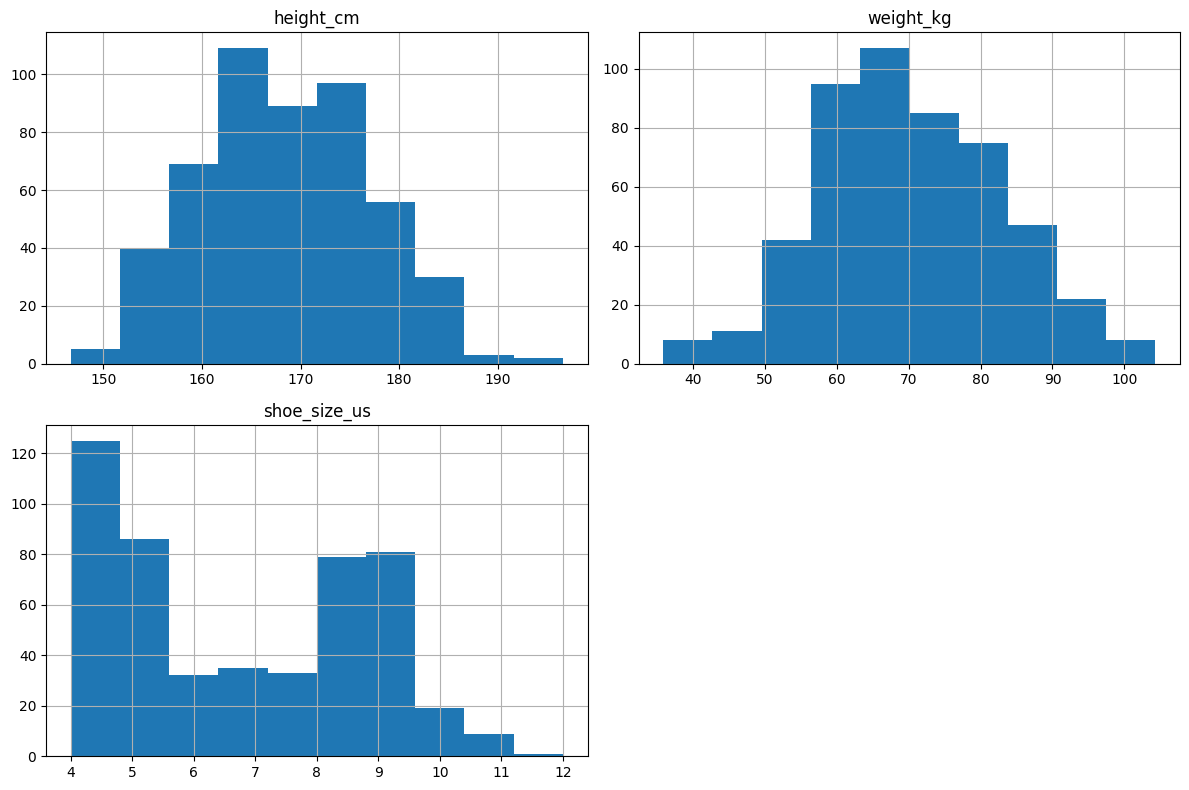

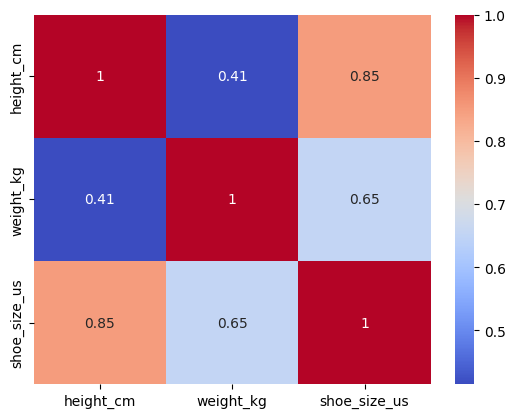

In [5]:
print(df.info())
display(df.describe(include="all").T)
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

sns.heatmap(df.select_dtypes("number").corr(),
            annot=True, cmap="coolwarm")
plt.show()

In [6]:
df = df.drop_duplicates().copy()

for col in df.columns:
    if df[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum())

height_cm       0
weight_kg       0
gender          0
shoe_size_us    0
dtype: int64


In [7]:
from sklearn.model_selection import train_test_split

target = input("Enter target column name: ").strip()

X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape)

StdinNotImplementedError: raw_input was called, but this frontend does not support input requests.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

numeric = ['height_cm', 'weight_kg']
categorical = ['gender']

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical)
])

models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(
        n_estimators=100, random_state=42
    )
}

trained_models = {}
results = []

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    trained_models[name] = pipe

    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2 Score': r2_score(y_test, pred)
    })

print("All models trained successfully!")


In [ ]:
results_df = pd.DataFrame(results)
display(results_df.round(3))

best_name = results_df.loc[
    results_df['RMSE'].idxmin(), 'Model'
]

best_model = trained_models[best_name]

print("Best Model:", best_name)


In [ ]:
import pickle

with open('/kaggle/working/aden_shoe_size_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)

with open('/kaggle/working/aden_shoe_size_model.pkl', 'rb') as f:
    loaded_model = pickle.load(f)

print("Model saved and loaded successfully!")
print("Model file: aden_shoe_size_model.pkl")

In [ ]:
new_person = pd.DataFrame({
    'height_cm': [175],
    'weight_kg': [70],
    'gender': ['Male']
})

prediction = loaded_model.predict(new_person)

print("Predicted US Shoe Size:", round(prediction[0], 2))
print("Created by: Aden Arshad")


In [ ]:
# 1. Check missing values
print("Missing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

# 2. Check missing values as percentages
print("\nMissing values percentage:")
missing_percent = (df.isnull().mean() * 100).round(2)
display(missing_percent.to_frame("Missing Percentage"))

# 3. Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# 4. Check unique values in each column
print("\nUnique values in each column:")
display(df.nunique().to_frame("Unique Values"))

In [ ]:
from sklearn.preprocessing import LabelEncoder

df = df.drop_duplicates().copy()

df['gender'] = LabelEncoder().fit_transform(df['gender'])

X = df.drop('shoe_size_us', axis=1)
y = df['shoe_size_us']

print("Features:", X.columns.tolist())
print("Target:", y.name)
display(df.head())

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    trained_models[name] = model

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2 Score": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

In [ ]:
import pickle

with open("/kaggle/working/aden_shoe_size_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

print("Model saved successfully!")

## Shoe Size Distribution

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df['shoe_size_us'], bins=15, kde=True)
plt.title('Shoe Size Distribution')
plt.xlabel('Shoe Size (US)')
plt.ylabel('Frequency')
plt.show()

In [ ]:
print("Dataset columns:")
print(df.columns.tolist())

## Height vs Shoe Size

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='height_cm', y='shoe_size_us', hue='gender')
plt.title('Height vs Shoe Size')
plt.show()

## Weight vs Shoe Size

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='gender', y='shoe_size_us')
plt.title('Gender-wise Shoe Size')
plt.show()

In [ ]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    df[['height_cm', 'weight_kg', 'shoe_size_us']].corr(),
    annot=True, cmap='coolwarm', fmt='.2f'
)
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x='Model', y='RMSE')
plt.title('Model Performance Comparison')
plt.ylabel('RMSE (Lower is Better)')
plt.xticks(rotation=15)
plt.show()